In [1]:
!pip -q install nltk wordcloud pyLDAvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 17.9 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
import re
import string
import nltk
import matplotlib.pyplot as plt

from collections import Counter
from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [6]:
!git clone -q https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing.git

import glob
import pandas as pd

files = glob.glob(
    "Health-Related-Headlines-Datasets-for-Natural-Language-Processing/**/*.csv",
    recursive=True
)

print("CSV files found:", len(files))
print("\n".join(files))

CSV files found: 30
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Adverse_Drug_Reaction_Perspective_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Patient_Safety_News_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_Management_Related_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Patient_Safety_Perspective_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Substance_Abuse_and_Addiction_Related_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Clinical_Trials_Perspective_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Pain_management_Features_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Adverse_Drug_Events_Related_Headlines.csv
Health-Related-Headlines-Datasets-for-Natural-Language-Processing/Patient_Safety_Related_Headlines.csv
Health-Relate

In [7]:
# Select the first CSV file
file_path = files[0]

df = pd.read_csv(file_path)

print("File loaded:", file_path.split("/")[-1])
print("Dataset shape:", df.shape)

File loaded: Adverse_Drug_Reaction_Perspective_Headlines.csv
Dataset shape: (1142, 4)


In [8]:
print("Columns:", list(df.columns))

Columns: ['Date', 'Source', 'Headlines', 'Teaser']


In [9]:
text_candidates = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ['headline', 'title', 'text', 'teaser', 'description'])
]

text_col = text_candidates[0]

print("Text column:", text_col)

Text column: Headlines


In [10]:
data = df[[text_col]].dropna().copy()
data[text_col] = data[text_col].astype(str)

print("Text records:", len(data))

Text records: 1142


In [11]:
import nltk

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

print("NLP resources ready.")

NLP resources ready.


In [12]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    tokens = nltk.word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens

data['tokens'] = data[text_col].apply(clean_text)
data['cleaned_text'] = data['tokens'].apply(lambda x: ' '.join(x))

print("Preprocessing completed.")

Preprocessing completed.


In [13]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)

    tokens = nltk.word_tokenize(text)

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return tokens

data['tokens'] = data[text_col].apply(clean_text)
data['cleaned_text'] = data['tokens'].apply(lambda x: ' '.join(x))

print("Preprocessing completed.")

Preprocessing completed.


In [14]:
for i, text in enumerate(data['cleaned_text'].head(5), 1):
    print(f"{i}. {text}")

1. using methotrexate dosage per week
2. managing patient develops urticaria medication
3. methamphetamine associated shock intestinal infarction
4. treatment drug allergy adrenaline
5. desensitization sulfa drug immunocompetent patient


In [15]:
from collections import Counter

all_words = [word for tokens in data['tokens'] for word in tokens]
word_freq = Counter(all_words)

print("Total words:", len(all_words))
print("Unique words:", len(word_freq))

Total words: 5594
Unique words: 2190


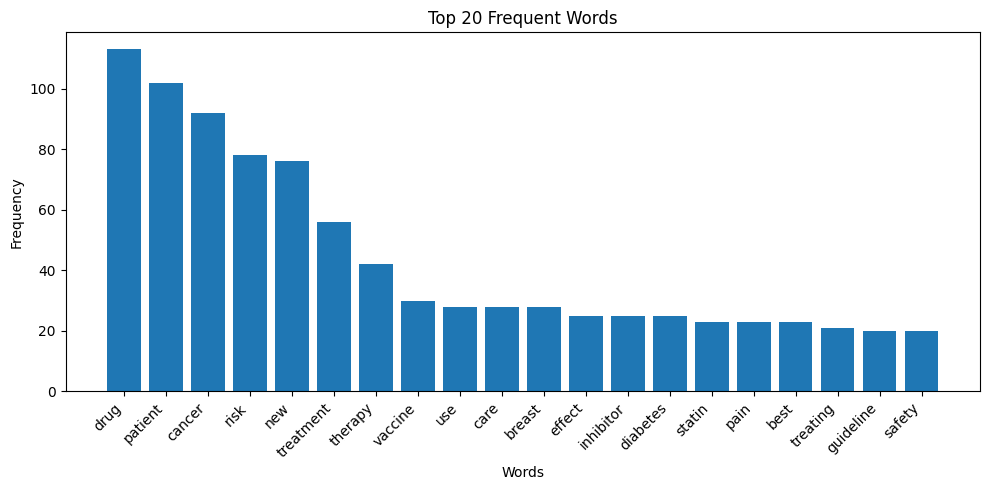

In [16]:
import matplotlib.pyplot as plt

top20 = word_freq.most_common(20)

words = [x[0] for x in top20]
counts = [x[1] for x in top20]

plt.figure(figsize=(10, 5))
plt.bar(words, counts)
plt.xticks(rotation=45, ha='right')
plt.title("Top 20 Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

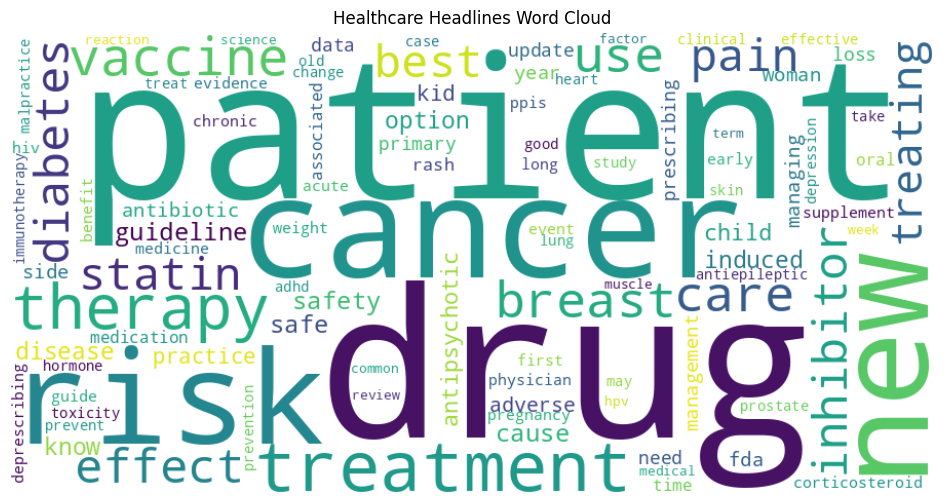

In [17]:
from wordcloud import WordCloud

wordcloud = WordCloud(
    width=900,
    height=450,
    background_color='white',
    max_words=100
).generate_from_frequencies(word_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Healthcare Headlines Word Cloud")
plt.show()

In [19]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=2
)

dtm = vectorizer.fit_transform(data['cleaned_text'])

print("Document-term matrix:", dtm.shape)

Document-term matrix: (1142, 830)


In [20]:
from sklearn.decomposition import LatentDirichletAllocation

lda = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    learning_method='batch'
)

lda.fit(dtm)

print("LDA model trained.")

LDA model trained.


In [22]:
terms = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-5:][::-1]
    words = [terms[j] for j in top_words]

    print(f"Topic {i + 1}: {', '.join(words)}")

Topic 1: patient, care, risk, statin, medicine
Topic 2: cancer, risk, breast, therapy, treatment
Topic 3: inhibitor, vaccine, treatment, know, effect
Topic 4: drug, patient, pain, new, loss
Topic 5: new, drug, cause, guideline, use


In [23]:
!pip -q install pyldavis

import pyLDAvis
import pyLDAvis.lda_model

pyLDAvis.enable_notebook()

print("pyLDAvis ready.")

pyLDAvis ready.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [25]:
vis = pyLDAvis.lda_model.prepare(
    lda,
    dtm,
    vectorizer,
    mds='pcoa'
)

vis

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
1      0.137447 -0.130691       1        1  22.146523
3     -0.157420 -0.042523       2        1  20.276233
4     -0.124936  0.054517       3        1  20.045166
2      0.111984  0.179260       4        1  19.729928
0      0.032925 -0.060563       5        1  17.802150, topic_info=           Term       Freq      Total Category  logprob  loglift
120      cancer  77.000000  77.000000  Default  30.0000  30.0000
234        drug  95.000000  95.000000  Default  29.0000  29.0000
514         new  64.000000  64.000000  Default  28.0000  28.0000
561     patient  86.000000  86.000000  Default  27.0000  27.0000
115      breast  24.000000  24.000000  Default  26.0000  26.0000
..          ...        ...        ...      ...      ...      ...
217    diabetes   4.336305  21.709375   Topic5  -5.1573   0.1151
292         fda   3.754320  13.401476   Topic5  -5.3014   0.4534
462  management   3.582990  13.345973   Topic5  -5.3481   0.4108
210    dementia   3.528987   5.857633   Topic5  -5.3633   1.2191
470         med   3.540343   8.360608   Topic5  -5.3601   0.8665

[296 rows x 6 columns], token_table=      Topic      Freq           Term
term                                
5         1  0.895606  acetaminophen
10        2  0.795837         acting
11        5  0.896890         action
12        1  0.099935          acute
12        2  0.199870          acute
...     ...       ...            ...
821       4  0.299471          woman
826       1  0.298916           year
826       3  0.448373           year
826       4  0.074729           year
826       5  0.224187           year

[410 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[2, 4, 5, 3, 1])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
topic_probs = lda.transform(dtm)

data['topic'] = topic_probs.argmax(axis=1) + 1

print(
    "Topic distribution:",
    data['topic'].value_counts().sort_index().to_dict()
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Topic distribution: {1: 222, 2: 246, 3: 245, 4: 221, 5: 208}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
data[[text_col, 'cleaned_text', 'topic']].to_csv(
    'Lab8_Cleaned_Healthcare_Data.csv',
    index=False
)

print("Processed dataset saved.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Processed dataset saved.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag